# 4.2. Configurando o ambiente

Instalando o pyspark na versão 3.3.4

In [2]:
%pip install pyspark==3.5.3

Note: you may need to restart the kernel to use updated packages.


Instalando a biblioteca Pydeequ  na versão 1.1.0

In [3]:
%pip install pydeequ

Note: you may need to restart the kernel to use updated packages.


Definindo a variável de ambiente do spark

In [4]:
import os
os.environ['SPARK_VERSION'] = '3.5.3'

Importando bibliotecas e funções importantes

In [5]:
import pydeequ
from pydeequ.analyzers import *
from pydeequ.verification import *
from pyspark.sql import SparkSession, Row
from pyspark.sql.functions import regexp_replace, expr

Criando a sessão spark com as configurações específicas da biblioteca pydeequ

In [6]:
spark = (
    SparkSession.builder
    .config("spark.jars.packages", pydeequ.deequ_maven_coord)
    .config("spark.jars.excludes", pydeequ.f2j_maven_coord)
    .getOrCreate()
)

26/09/05 02:42:50 WARN Utils: Your hostname, robot resolves to a loopback address: 127.0.1.1; using 192.168.0.15 instead (on interface wlx001f0574f2b9)
26/09/05 02:42:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/home/felipe/Documentos/Carreira-Alura/Governan%c3%a7a%20de%20dados/.venv/lib/python3.14/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/felipe/.ivy2/cache
The jars for the packages stored in: /home/felipe/.ivy2/jars
com.amazon.deequ#deequ added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-047c6a34-f99e-468f-aac4-b91e4cab53ae;1.0
	confs: [default]
	found com.amazon.deequ#deequ;2.0.8-spark-3.5 in central
	found org.scala-lang#scala-reflect;2.12.10 in central
	found org.scalanlp#breeze_2.12;2.1.0 in central
	found org.scalanlp#breeze-macros_2.12;2.1.0 in central
	found org.typelevel#spire_2.12;0.17.0 in central
	found org.typelevel#spire-macros_2.12;0.17.0 in central
	found org.typelevel#algebra_2.12;2.0.1 in central
	found org.typelevel#cats-kernel_2.12;2.1.1 in central
	found org.typelevel#spire-platform_2.12;0.17.0 in central
	found org.typelevel#spire-util_2.12;0.17.0 in central
	found dev.ludovic.netlib#blas;3.0.1 in central
	found dev.ludovic.netlib#lapack;3.0.1 in central
	found dev.ludovic.netlib#arpack;3.0.1 in central
	found net.sf.opencsv#open

In [7]:
spark


# 4.3 -  Conhecendo os dados

Trazendo os dados para o ambiente de desenvolvimento

In [8]:
df = spark.read \
    .option("header", "true") \
    .option("delimiter", ";") \
    .option('encoding', 'UTF-16') \
    .csv('./dados_bilheteria_filmes/bilheteria-diaria-obras-por-distribuidoras-2023-12.csv')

Alocando os dados em um Spark Dataframe

In [9]:
df.show(5)

+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+-------------------+
|DATA_EXIBICAO|     TITULO_ORIGINAL|      TITULO_BRASIL|       CPB_ROE|     PAIS_OBRA|REGISTRO_SALA|           NOME_SALA|PUBLICO|REGISTRO_GRUPO_EXIBIDOR|REGISTRO_EXIBIDOR|REGISTRO_COMPLEXO|MUNICIPIO_SALA_COMPLEXO|UF_SALA_COMPLEXO|RAZAO_SOCIAL_DISTRIBUIDORA|CNPJ_DISTRIBUIDORA�|
+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+-------------------+
|   01/12/2023|ABELHA GIRL A SUP...|               NULL|B2300132300000|        BRASIL|         NULL|luciano da luz mo...|    350|                   NULL|             

Conhecendo os dados

In [10]:
df.dtypes

[('DATA_EXIBICAO', 'string'),
 ('TITULO_ORIGINAL', 'string'),
 ('TITULO_BRASIL', 'string'),
 ('CPB_ROE', 'string'),
 ('PAIS_OBRA', 'string'),
 ('REGISTRO_SALA', 'string'),
 ('NOME_SALA', 'string'),
 ('PUBLICO', 'string'),
 ('REGISTRO_GRUPO_EXIBIDOR', 'string'),
 ('REGISTRO_EXIBIDOR', 'string'),
 ('REGISTRO_COMPLEXO', 'string'),
 ('MUNICIPIO_SALA_COMPLEXO', 'string'),
 ('UF_SALA_COMPLEXO', 'string'),
 ('RAZAO_SOCIAL_DISTRIBUIDORA', 'string'),
 ('CNPJ_DISTRIBUIDORA�', 'string')]

# 4.4 - Resolvendo problemas com o DataFrame

Renomeando a coluna CNPJ

In [11]:
df = df.withColumnRenamed(df.columns[-1], df.columns[-1][:-1])

In [12]:
df.show(2)

+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+-------------------+
|DATA_EXIBICAO|     TITULO_ORIGINAL|      TITULO_BRASIL|       CPB_ROE|     PAIS_OBRA|REGISTRO_SALA|           NOME_SALA|PUBLICO|REGISTRO_GRUPO_EXIBIDOR|REGISTRO_EXIBIDOR|REGISTRO_COMPLEXO|MUNICIPIO_SALA_COMPLEXO|UF_SALA_COMPLEXO|RAZAO_SOCIAL_DISTRIBUIDORA| CNPJ_DISTRIBUIDORA|
+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+-------------------+
|   01/12/2023|ABELHA GIRL A SUP...|               NULL|B2300132300000|        BRASIL|         NULL|luciano da luz mo...|    350|                   NULL|             

Editando os registros para retirar o caractere extra

In [13]:
df = df.withColumn('CNPJ_DISTRIBUIDORA', expr("substring(CNPJ_DISTRIBUIDORA, 1, length(CNPJ_DISTRIBUIDORA)-1)"))

In [14]:
df.show(5)

+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+------------------+
|DATA_EXIBICAO|     TITULO_ORIGINAL|      TITULO_BRASIL|       CPB_ROE|     PAIS_OBRA|REGISTRO_SALA|           NOME_SALA|PUBLICO|REGISTRO_GRUPO_EXIBIDOR|REGISTRO_EXIBIDOR|REGISTRO_COMPLEXO|MUNICIPIO_SALA_COMPLEXO|UF_SALA_COMPLEXO|RAZAO_SOCIAL_DISTRIBUIDORA|CNPJ_DISTRIBUIDORA|
+-------------+--------------------+-------------------+--------------+--------------+-------------+--------------------+-------+-----------------------+-----------------+-----------------+-----------------------+----------------+--------------------------+------------------+
|   01/12/2023|ABELHA GIRL A SUP...|               NULL|B2300132300000|        BRASIL|         NULL|luciano da luz mo...|    350|                   NULL|             NUL

Verificando o Schema do DataFrame

In [15]:
df.printSchema()

root
 |-- DATA_EXIBICAO: string (nullable = true)
 |-- TITULO_ORIGINAL: string (nullable = true)
 |-- TITULO_BRASIL: string (nullable = true)
 |-- CPB_ROE: string (nullable = true)
 |-- PAIS_OBRA: string (nullable = true)
 |-- REGISTRO_SALA: string (nullable = true)
 |-- NOME_SALA: string (nullable = true)
 |-- PUBLICO: string (nullable = true)
 |-- REGISTRO_GRUPO_EXIBIDOR: string (nullable = true)
 |-- REGISTRO_EXIBIDOR: string (nullable = true)
 |-- REGISTRO_COMPLEXO: string (nullable = true)
 |-- MUNICIPIO_SALA_COMPLEXO: string (nullable = true)
 |-- UF_SALA_COMPLEXO: string (nullable = true)
 |-- RAZAO_SOCIAL_DISTRIBUIDORA: string (nullable = true)
 |-- CNPJ_DISTRIBUIDORA: string (nullable = true)



Alterando o tipo de dado da coluna "Publico"

In [16]:
df = df.withColumn('PUBLICO', df['PUBLICO'].cast('integer'))

In [17]:
df.printSchema()

root
 |-- DATA_EXIBICAO: string (nullable = true)
 |-- TITULO_ORIGINAL: string (nullable = true)
 |-- TITULO_BRASIL: string (nullable = true)
 |-- CPB_ROE: string (nullable = true)
 |-- PAIS_OBRA: string (nullable = true)
 |-- REGISTRO_SALA: string (nullable = true)
 |-- NOME_SALA: string (nullable = true)
 |-- PUBLICO: integer (nullable = true)
 |-- REGISTRO_GRUPO_EXIBIDOR: string (nullable = true)
 |-- REGISTRO_EXIBIDOR: string (nullable = true)
 |-- REGISTRO_COMPLEXO: string (nullable = true)
 |-- MUNICIPIO_SALA_COMPLEXO: string (nullable = true)
 |-- UF_SALA_COMPLEXO: string (nullable = true)
 |-- RAZAO_SOCIAL_DISTRIBUIDORA: string (nullable = true)
 |-- CNPJ_DISTRIBUIDORA: string (nullable = true)



# 4.5 Criando  o primeiro Analyzer

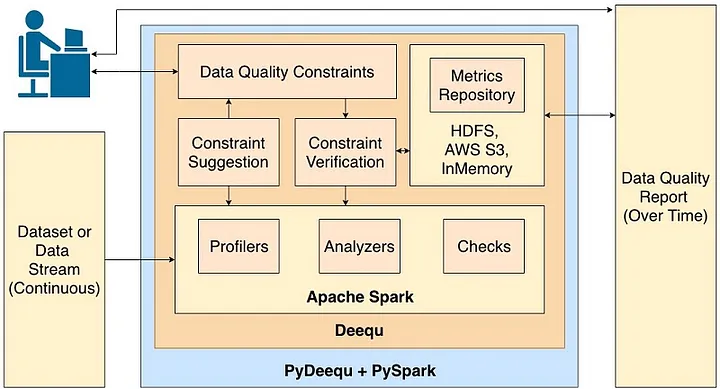

Na biblioteca Pydeequ, temos três tipos principais de analyzers:
1. Do dataset todo
2. De colunas específicas
3. De comparação

Analyzers de dataset são aqueles que trazem informações sobre todo o dataset. O mais simples deles é o Size(), que retorna a quantidade de linhas do dataset

Analysers de colunas específicas trazem informações daquelas colunas. Um exemplo é o Completeness(), que retorna a razão de linhas não nulas.

Annalysers de comparação comparam informações de duas ou mais colunas do dataset. Um exemplo é o Correlation(), que retorna a correlação de pearson dada duas colunas.

Criando o primeiro Analyzer

In [36]:
resultado_analise = (
    AnalysisRunner(spark)
    .onData(df)
    .addAnalyzer(Size())
    .addAnalyzer(Completeness('NOME_SALA'))
    .addAnalyzer(Completeness('PUBLICO'))
    .addAnalyzer(Mean('PUBLICO'))
    .addAnalyzer(CountDistinct('MUNICIPIO_SALA_COMPLEXO'))
    .addAnalyzer(Compliance('PUBLICO', 'PUBLICO > 10'))
    .run()
)

Trabalhando com os resultados de um Analyzer

In [37]:
resultado_df = AnalyzerContext.successMetricsAsDataFrame(spark, resultado_analise)
resultado_df.show()

+-------+--------------------+-------------+------------------+
| entity|            instance|         name|             value|
+-------+--------------------+-------------+------------------+
| Column|           NOME_SALA| Completeness|               1.0|
| Column|             PUBLICO|         Mean|44.088970640254686|
|Dataset|                   *|         Size|          141350.0|
| Column|             PUBLICO| Completeness|               1.0|
| Column|MUNICIPIO_SALA_CO...|CountDistinct|             443.0|
| Column|             PUBLICO|   Compliance|0.6735267067562788|
+-------+--------------------+-------------+------------------+



In [ ]:
tarefa = (
    AnalysisRunner(spark)
    .onData(df)
    .addAnalyzer(
        ApproxCountDistinct(
            'MUNICIPIO_SALA_COMPLEXO'
            #,where="substring('DATA_EXIBICAO', 4, 2) == '12'"
            ))
    .addAnalyzer(CountDistinct('MUNICIPIO_SALA_COMPLEXO'))
    .run()
)

_IncompleteInputError: incomplete input (1076962839.py, line 10)

In [47]:
tarefa_df = AnalyzerContext.successMetricsAsDataFrame(spark, tarefa)
tarefa_df.show()

+------+--------------------+--------------------+-----+
|entity|            instance|                name|value|
+------+--------------------+--------------------+-----+
|Column|MUNICIPIO_SALA_CO...|ApproxCountDistin...|  0.0|
|Column|MUNICIPIO_SALA_CO...|       CountDistinct|443.0|
+------+--------------------+--------------------+-----+



/home/felipe/Documentos/Carreira-Alura/Governança de dados/.venv/lib/python3.14/site-packages/pyspark/sql/dataframe.py:147: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


# 5.1 - Criando Profiles

Importando a parte de profiles da biblioteca

Criando um Profile para algumas colunas

Verificando o resultado de um profile

Visualizando o resultado do profile

#5.2 Checks

Importando as funções importantes para usar os Checks

Criando um Check padrão

Criando um teste com o Check

Trabalhando com os resultados de um teste

Visualizando os resultados de um check com Pandas

# 5. Criando um check passando por todas as dimensões de qualidade:

## 1. Acurácia

- Acurácia pode ser difícil de ser traduzida em regras, pois normalmente, se necessita de uma fonte externa de informação para que possam confirmar as informações.
Nesse caso, vamos criar algumas regras de compliance, para garantir que os dados não reflitam uma realidade absurda

Criando função que verifica a acurácia

Salvando os resultados em uma variável

Analisando os resultados

Criando uma função que corrige os demais meses

Testando a regra para outros meses

Corrigindo os problemas com o dataFrame

Aplicando o teste de acurácia com os para os demais meses

Entendendo os problemas

## 2. Validade

Criando a função que verifica validade

Aplicando a função criada

Analisando os resultados

## 3. Completude

Criando a função que verifica a completude

Analisando resultados

## 4. Unicidade

Criando a função que verifica unicidade

Analisando os resultadados

## 5. Consistência

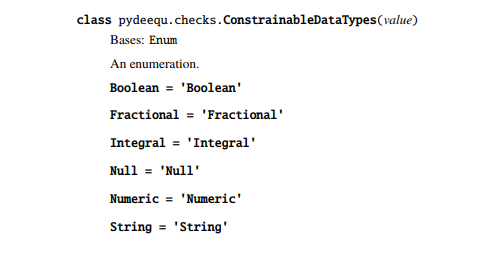

Criando função que verifica a consistência

Aplicando em algumas colunas

## 6. Temporalidade

Ao invés de criar um check nós mesmos para temporalidade, vamos verificar o que a biblioteca Pydeequ nos sugere como testes para essa coluna

Criando sugestões para testes

Analisando as sugestões dadas